In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
# Plotting style setup
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"

In [35]:
df = pd.read_csv("answer_evaluation.csv")
df.head()

,question_id,answer_text,expected_concepts,answer_length,keyword_coverage,tfidf_similarity,semantic_similarity,concept_coverage,relevance_score,human_score,quality_class
0,101,Vanishing gradients occur during backpropagati...,vanishing gradient exploding gradient backprop...,76,0.840,0.280,0.499,0.826,0.411,94.0,Excellent
1,101,Vanishing gradient happens when gradients beco...,vanishing gradient exploding gradient backprop...,36,0.480,0.242,0.317,0.435,0.287,78.0,Good
2,101,Vanishing gradient is an error in deep network...,vanishing gradient exploding gradient backprop...,26,0.259,0.097,0.144,0.217,0.125,46.0,Average
3,101,Gradient disappears because network is too big.,vanishing gradient exploding gradient backprop...,7,0.136,0.116,0.118,0.130,0.117,20.0,Poor
4,102,Scaled Dot-Product Attention computes attentio...,query key value dot product matrix multiplicat...,66,0.415,0.210,0.269,0.364,0.245,96.0,Excellent


In [36]:
# Statistical Summary
print("--- Data Info & Missing Values ---")
print(df.info())
print("\nMissing Values Count:\n", df.isnull().sum())

print("\n--- Descriptive Statistics ---")
df.describe().T[["mean", "std", "min", "50%", "max"]]

--- Data Info & Missing Values ---
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   question_id          120 non-null    int64  
 1   answer_text          120 non-null    str    
 2   expected_concepts    120 non-null    str    
 3   answer_length        120 non-null    int64  
 4   keyword_coverage     120 non-null    float64
 5   tfidf_similarity     120 non-null    float64
 6   semantic_similarity  120 non-null    float64
 7   concept_coverage     120 non-null    float64
 8   relevance_score      120 non-null    float64
 9   human_score          120 non-null    float64
 10  quality_class        120 non-null    str    
dtypes: float64(6), int64(2), str(3)
memory usage: 57.3 KB
None

Missing Values Count:
 question_id            0
answer_text            0
expected_concepts      0
answer_length          0
keyword_coverage       0
tfidf_si

,mean,std,min,50%,max
question_id,212.600000,83.716448,101.000,203.0000,305.000
answer_length,31.266667,22.948878,4.000,24.0000,82.000
keyword_coverage,0.302125,0.219552,0.011,0.2620,0.840
tfidf_similarity,0.191158,0.122273,0.000,0.1820,0.457
semantic_similarity,0.235292,0.157253,0.000,0.2055,0.558
concept_coverage,0.305042,0.225707,0.000,0.2445,0.870
relevance_score,0.217633,0.140387,0.000,0.1960,0.484
human_score,62.022500,29.103693,15.100,65.8500,99.300


In [37]:
print(df.columns.tolist())

['question_id', 'answer_text', 'expected_concepts', 'answer_length', 'keyword_coverage', 'tfidf_similarity', 'semantic_similarity', 'concept_coverage', 'relevance_score', 'human_score', 'quality_class']


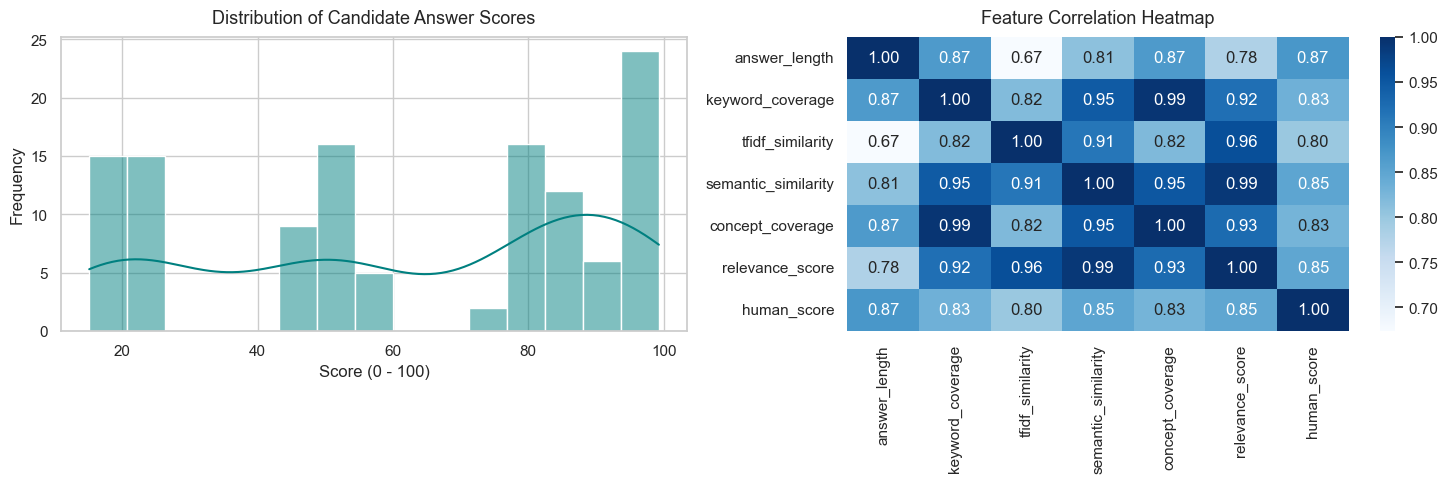

In [38]:
# Check feature columns
features_to_check = [
    "answer_length", "keyword_coverage", "tfidf_similarity",
    "semantic_similarity", "concept_coverage", "relevance_score",
    "human_score"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Distribution of Human Scores
sns.histplot(df["human_score"], kde=True, color="#008080", ax=axes[0], bins=15)
axes[0].set_title("Distribution of Candidate Answer Scores", fontsize=13, pad=10)
axes[0].set_xlabel("Score (0 - 100)")
axes[0].set_ylabel("Frequency")

# 2. Correlation Heatmap
corr_matrix = df[features_to_check].corr()

sns.heatmap(corr_matrix, annot=True, cmap="Blues", fmt=".2f", ax=axes[1], cbar=True)
axes[1].set_title("Feature Correlation Heatmap", fontsize=13, pad=10)

plt.tight_layout()
plt.show()

In [39]:
print(df.columns)

Index(['question_id', 'answer_text', 'expected_concepts', 'answer_length',
       'keyword_coverage', 'tfidf_similarity', 'semantic_similarity',
       'concept_coverage', 'relevance_score', 'human_score', 'quality_class'],
      dtype='str')


In [40]:
import pandas as pd
import numpy as np

# 1. Dataset load karna
df = pd.read_csv("answer_evaluation.csv")

# 2. Keyword Coverage calculate karne ka function
def calculate_keyword_coverage(answer, keywords):
    if not keywords or pd.isna(answer):
        return 0.0
    if isinstance(keywords, str):
        keywords = [kw.strip() for kw in keywords.split(',')]
        
    matched_count = sum(1 for kw in keywords if str(kw).lower() in str(answer).lower())
    coverage = matched_count / len(keywords)
    return coverage

# Keyword coverage calculate karke column update karna
df['keyword_coverage'] = df.apply(
    lambda row: calculate_keyword_coverage(row['answer_text'], row['expected_concepts']), 
    axis=1
)

# 3. Agar answer_length calculate karni ho (agar pehle se na ho)
df['answer_length'] = df['answer_text'].astype(str).apply(lambda x: len(x.split()))

# 4. Model ke liye features (X) aur target (y) define karna
feature_cols = [
    "answer_length", 
    "keyword_coverage",
    "tfidf_similarity", 
    "semantic_similarity", 
    "concept_coverage", 
    "relevance_score"
]

X = df[feature_cols]
y = df["human_score"]

print("🎉 Saare features successfully calculate aur prepare ho gaye hain!")
print("Features shape (X):", X.shape)

🎉 Saare features successfully calculate aur prepare ho gaye hain!
Features shape (X): (120, 6)


In [41]:
from sklearn.model_selection import train_test_split

feature_cols = [
    "answer_length",
    "keyword_coverage",
    "tfidf_similarity",
    "semantic_similarity",
    "concept_coverage",
    "relevance_score"
]

X = df[feature_cols]
y = df["human_score"]

# 80% Train, 20% Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")

Training samples: 96 | Testing samples: 24


In [42]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

Training Shape: (96, 6)
Testing Shape: (24, 6)


In [43]:
# Check missing values
print("Missing values:")
print(X_train.isnull().sum().sum())

# Check infinite values (numeric columns only)
print("\nInfinite values:")
numeric_data = X_train.select_dtypes(include=np.number)
print(np.isinf(numeric_data).sum().sum())

# Check duplicate rows
print("\nDuplicate rows:", X_train.duplicated().sum())

# Check target distribution
print("\nTarget Summary:")
print(y_train.describe())

Missing values:
0

Infinite values:
0

Duplicate rows: 4

Target Summary:
count    96.000000
mean     61.477083
std      28.487617
min      15.100000
25%      40.200000
50%      65.850000
75%      85.000000
max      99.300000
Name: human_score, dtype: float64


In [44]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor, 
    GradientBoostingRegressor, 
    ExtraTreesRegressor, 
    StackingRegressor, 
    VotingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Base Estimators for Ensembling
base_estimators = [
    ('et', ExtraTreesRegressor(n_estimators=150, max_depth=6, random_state=42)),
    ('rf', RandomForestRegressor(n_estimators=150, max_depth=6, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=120, learning_rate=0.05, max_depth=3, random_state=42))
]

In [45]:
models = {
    "Linear Regression": LinearRegression(),
    "Standard Random Forest": RandomForestRegressor(n_estimators=150, max_depth=6, random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(n_estimators=120, learning_rate=0.05, max_depth=3, random_state=42),
    "Extra Trees Regressor": ExtraTreesRegressor(n_estimators=150, max_depth=6, random_state=42),
    "Voting Ensemble (RF+GB+ET)": VotingRegressor(estimators=base_estimators),
    "Stacking Regressor (Champion Architecture)": StackingRegressor(estimators=base_estimators, final_estimator=Ridge(alpha=0.5))
}

results = []
best_model = None
best_r2 = -float("inf")
best_name = ""

for name, m in models.items():
    m.fit(X_train, y_train)
    preds = m.predict(X_test)
    
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    acc_within_5_pts = np.mean(np.abs(preds - y_test) <= 5.0) * 100
    
    results.append({
        "Model": name,
        "MAE (Lower=Better)": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score (Higher=Better)": round(r2, 4),
        "Accuracy (±5 pts)": f"{acc_within_5_pts:.1f}%"
    })
    
    if r2 > best_r2:
        best_r2 = r2
        best_model = m
        best_name = name

benchmark_df = pd.DataFrame(results).sort_values(by="R2 Score (Higher=Better)", ascending=False)
print("=== ALGORITHM BENCHMARK REPORT ===")
print(benchmark_df.to_string(index=False))
print(f"\nChampion Architecture Selected: {best_name} (R² = {best_r2:.4f})")

=== ALGORITHM BENCHMARK REPORT ===
                                     Model  MAE (Lower=Better)  RMSE  R2 Score (Higher=Better) Accuracy (±5 pts)
Stacking Regressor (Champion Architecture)                2.65  4.41                    0.9802             91.7%
                     Extra Trees Regressor                2.84  4.59                    0.9786             91.7%
                Voting Ensemble (RF+GB+ET)                3.20  5.95                    0.9639             87.5%
               Gradient Boosting Regressor                3.16  6.65                    0.9550             91.7%
                    Standard Random Forest                3.84  7.22                    0.9469             83.3%
                         Linear Regression               10.32 11.76                    0.8592             16.7%

Champion Architecture Selected: Stacking Regressor (Champion Architecture) (R² = 0.9802)


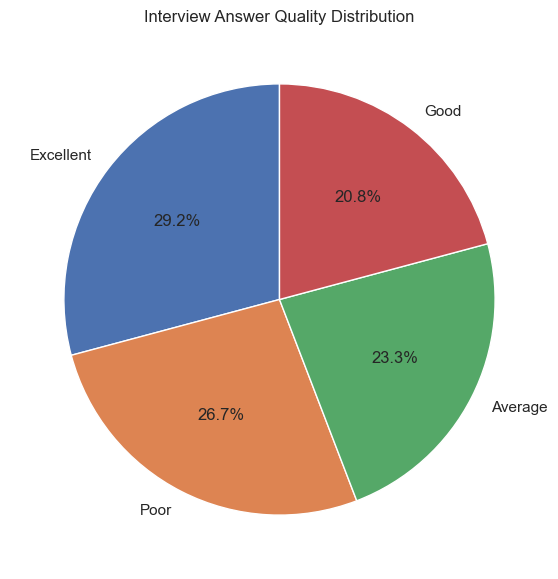

In [46]:
plt.figure(figsize=(7, 7))

df["quality_class"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

plt.title("Interview Answer Quality Distribution")
plt.ylabel("")

plt.savefig("Quality_Class_Pie_Chart.png", dpi=300)
plt.show()

In [47]:
importance = best_model.feature_importances_

feature_importance = pd.Series(
    importance,
    index=X_train.columns
).sort_values()

feature_importance.plot(
    kind="barh",
    figsize=(8, 5),
    title="Extra Trees Feature Importance"
)

plt.xlabel("Importance Score")
plt.tight_layout()
plt.savefig("Feature_Importance.png", dpi=300)
plt.show()

AttributeError: 'StackingRegressor' object has no attribute 'feature_importances_'

In [ ]:
y_pred = best_model.predict(X_test)

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([0, 100], [0, 100], "r--")

plt.xlabel("Actual Human Score")
plt.ylabel("Predicted Score")
plt.title("Actual vs Predicted Scores")

plt.savefig("Actual_vs_Predicted.png", dpi=300)
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df["human_score"], bins=10, edgecolor="black")

plt.xlabel("Human Score")
plt.ylabel("Number of Answers")
plt.title("Distribution of Human Evaluation Scores")

plt.savefig("Score_Distribution.png", dpi=300)
plt.show()

In [48]:
import joblib

# 1. Best model ko file mein save (.dump) karna
model_filename = "ai_mock_interview_champion_model.pkl"
joblib.dump(best_model, model_filename)

print(f"🎉 Model successfully dump/save ho gaya hai: {model_filename}")

# 2. Agar baad mein kabhi model ko wapas load (.load) karna ho toh:
# loaded_model = joblib.load(model_filename)

🎉 Model successfully dump/save ho gaya hai: ai_mock_interview_champion_model.pkl
